# Sumar riesgos: la suma simple, varianza-covarianza y un primer beneficio de diversificación

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el cuaderno 01 del tema 01 (abrir un artefacto versionado); no se necesita otro tema
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer las cuatro marginales de Banco Andino (crédito, mercado, riesgo de tasa de interés en la cartera de inversión y riesgo operacional) de un documento versionado y decir qué son su pérdida esperada, su VaR, su pérdida esperada en la cola y su capital económico;
- sumar los cuatro capitales de las dos maneras más simples, la suma simple (dependencia perfecta) y la regla de la raíz cuadrada con una matriz de correlación entre riesgos, y comprobar ambas con la banda versionada del motor;
- explicar por qué una matriz de correlación debe validarse antes de usarla, y ver al motor rechazar tres inválidas;
- convertir un total en un factor de diversificación y un beneficio, ver cómo el beneficio se agota cuando sube la correlación, y leer el beneficio que recibe cada riesgo;
- explicar por qué la suma simple no es una cota superior para un VaR, con el peor caso versionado como evidencia.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from riskvalidation.aggregation import simple
for name in ("riskvalidation", "numpy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Este cuaderno lee el caso de capital y estrés de Contraste, **C18**: cuánto capital necesita un banco una vez sumados sus riesgos, y cuánto de la respuesta depende de la forma de sumarlos.

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (el escenario base: su bloque `outputs.aggregation` tiene las cuatro marginales, la matriz de correlación, la banda de métodos de agregación, la asignación de Euler y la diversificación) y `data/derived/C18/t-copula-baseline.json` (la misma agregación con la referencia de Rosenberg y Schuermann). Toda ruta es relativa a la raíz del repositorio.
- **Lo que el documento no tiene:** el millón de pérdidas simuladas detrás de cada marginal. Tiene cuatro números resumen por marginal, que es todo lo que necesita este cuaderno; los cuadernos 02 y 03 de este tema reconstruyen una simulación a partir de ellos.

La celda siguiente encuentra la raíz del repositorio (el cuaderno está tres carpetas bajo ella) y define un lector que se detiene con la ruta del archivo cuando falta uno.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

carpeta derived encontrada: sí


## Método

### Paso 1: el capital de cada riesgo

Contraste mide cada riesgo a **un año y al nivel de 99,9 por ciento** y trabaja con el **capital económico**, la pérdida inesperada: el VaR de la distribución de pérdidas menos su pérdida esperada,

$$EC = \mathrm{VaR}_{0.999}(L) - \mathrm{EL}.$$

La pérdida esperada en la cola (ES) es la pérdida media más allá del VaR. El documento tiene los cuatro números de cada riesgo, en millones de CLP. La celda siguiente los lee, comprueba que $EC = \mathrm{VaR} - \mathrm{EL}$ se cumple en el documento e imprime la procedencia del horneado.

In [3]:
# Leer el documento base, imprimir las cuatro marginales y comprobar EC = VaR - EL en cada una
baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
print("base de capital:", agg["capital_basis"], "| horizonte (años):", agg["horizon_years"], "| nivel:", agg["confidence_level"])
print("horneado con riskvalidation", baseline["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print(f'{"riesgo":12s} {"EL":>10s} {"VaR":>10s} {"ES":>10s} {"EC":>10s}  EC = VaR - EL')
for m in agg["marginals"]:
    holds = bool(np.isclose(m["var_clp_m"] - m["el_clp_m"], m["ec_clp_m"]))
    print(f'{m["risk"]:12s} {m["el_clp_m"]:10,.0f} {m["var_clp_m"]:10,.0f} {m["es_clp_m"]:10,.0f} {m["ec_clp_m"]:10,.0f}  {sino(holds)}')

base de capital: economic-capital-var-less-el | horizonte (años): 1 | nivel: 0.999
horneado con riskvalidation 0.9.0 | instalado 0.9.0
riesgo               EL        VaR         ES         EC  EC = VaR - EL
credit           37,619    298,227    346,949    260,607  sí
market                0    283,435    355,803    283,435  sí
irrbb            27,922    100,746    106,382     72,824  sí
operational       1,188     42,367    171,091     41,179  sí


### Paso 2: la suma simple

El total más simple suma los cuatro capitales,

$$EC_{\text{tot}} = \sum_k EC_k.$$

Supone que los cuatro malos años llegan siempre juntos (dependencia perfecta), y es el **capital principal** del caso: la autoevaluación interna chilena suma el capital necesario por cada riesgo. Toda otra cifra de este cuaderno es información que se muestra al lado, nunca un reemplazo. La celda siguiente calcula la suma con `simple_sum` del motor y la compara con el capital principal que declara el documento.

In [4]:
# Sumar los cuatro capitales económicos con el motor y compararlos con el capital principal versionado
risks = [m["risk"] for m in agg["marginals"]]
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
total_simple = simple.simple_sum(ec)
print("capitales económicos:", {risk: round(float(value)) for risk, value in zip(risks, ec)})
print("suma simple (motor):", round(total_simple, 3))
print("principal versionado:", round(agg["headline"]["capital_clp_m"], 3), "| método:", agg["headline"]["method"])
print("coinciden:", sino(np.isclose(total_simple, agg["headline"]["capital_clp_m"])))

capitales económicos: {'credit': 260607, 'market': 283435, 'irrbb': 72824, 'operational': 41179}
suma simple (motor): 658045.991
principal versionado: 658045.991 | método: simple-sum
coinciden: sí


### Paso 3: la matriz de correlación entre riesgos

Los malos años no siempre coinciden, así que un banco puede sumar los capitales con una matriz de correlación $R$. La matriz de este caso es una convención tomada de Rosenberg y Schuermann (2006): mercado con crédito 0,5, mercado y crédito con riesgo operacional 0,2, y el documento extiende el 0,5 al riesgo de tasa de interés. Una matriz solo sirve si es simétrica, tiene diagonal unitaria, entradas en $[-1, 1]$ y ningún valor propio negativo (semidefinida positiva). `check_correlation` comprueba las cuatro cosas y lanza `ValueError` si falla alguna. La celda siguiente imprime la matriz versionada, la valida y muestra el rechazo de tres matrices inválidas. Los mensajes son los del propio motor, en inglés.

In [5]:
# Imprimir la matriz de correlación versionada, validarla y mostrar el rechazo de tres matrices inválidas
R = np.array(agg["correlation"]["matrix"])
print("orden:", agg["correlation"]["order"], "| rótulo:", agg["correlation"]["label"])
print(R)
simple.check_correlation(R)
print("la matriz versionada pasa check_correlation; menor valor propio:", round(float(np.linalg.eigvalsh(R)[0]), 4))
# el motor escribe sus mensajes en inglés; esta tabla da su traducción y falla (KeyError) si el motor cambia el texto
TRADUCCION = {
    "corr must be positive semi-definite (smallest eigenvalue -0.8)": "corr debe ser semidefinida positiva (menor valor propio -0.8)",
    "corr must be symmetric": "corr debe ser simétrica",
    "corr must have a unit diagonal": "corr debe tener diagonal unitaria",
}
invalid = {
    "no semidefinida positiva": [[1, 0.9, -0.9], [0.9, 1, 0.9], [-0.9, 0.9, 1]],
    "no simétrica": [[1, 0.5], [0.2, 1]],
    "la diagonal no es 1": [[2, 0.5], [0.5, 1]],
}
for why, matrix in invalid.items():
    try:
        simple.check_correlation(np.array(matrix, dtype=float))
        print(why, ": aceptada")
    except ValueError as err:
        print(f"{why}: rechazada: {TRADUCCION[str(err)]}")

orden: ['credit', 'market', 'irrbb', 'operational'] | rótulo: convention
[[1.  0.5 0.5 0.2]
 [0.5 1.  0.5 0.2]
 [0.5 0.5 1.  0.2]
 [0.2 0.2 0.2 1. ]]
la matriz versionada pasa check_correlation; menor valor propio: 0.5
no semidefinida positiva: rechazada: corr debe ser semidefinida positiva (menor valor propio -0.8)
no simétrica: rechazada: corr debe ser simétrica
la diagonal no es 1: rechazada: corr debe tener diagonal unitaria


### Paso 4: varianza-covarianza, la regla de la raíz cuadrada

Con una matriz válida el capital total es

$$EC_{\text{tot}} = \sqrt{EC^{\top} R \, EC} = \sqrt{\sum_{j}\sum_{k} R_{jk}\, EC_j\, EC_k}.$$

Es exacta cuando las pérdidas son elípticas con un escalamiento de cuantiles común, y una aproximación en otro caso (dossier 05, G.1). Dos límites muestran qué hace la regla: con $R = I$ (riesgos independientes) es la raíz de la suma de cuadrados, y con $R$ de puros unos (dependencia perfecta) es la suma simple. La celda siguiente imprime la forma cuadrática paso a paso, llama a `variance_covariance` y la compara con la fila de la banda versionada.

In [6]:
# La forma cuadrática a mano, la llamada al motor, los dos límites y la fila de la banda versionada
quadratic = float(ec @ R @ ec)
print("EC' R EC =", round(quadratic, 1), "| su raíz cuadrada =", round(quadratic ** 0.5, 3))
total_vc = simple.variance_covariance(ec, R)
band = {(row["method"], row["nu"]): row for row in agg["band"]}
print("variance_covariance (motor):", round(total_vc, 3))
print("fila de la banda versionada:", round(band[("variance-covariance", None)]["capital_clp_m"], 3))
print("R = identidad:", round(simple.variance_covariance(ec, np.eye(4)), 3), "| raíz de la suma de cuadrados:", round(float(np.sqrt((ec ** 2).sum())), 3))
print("R = puros unos:", round(simple.variance_covariance(ec, np.ones((4, 4))), 3), "| suma simple:", round(total_simple, 3))

EC' R EC = 278896364406.0 | su raíz cuadrada = 528106.395
variance_covariance (motor): 528106.395
fila de la banda versionada: 528106.395
R = identidad: 394018.896 | raíz de la suma de cuadrados: 394018.896
R = puros unos: 658045.991 | suma simple: 658045.991


### Paso 5: el factor de diversificación y qué lo mueve

El **factor de diversificación** es el total sobre la suma de los capitales por separado,

$$DF = \frac{\rho(L)}{\sum_k \rho(L_k)},$$

y el **beneficio** es $1 - DF$. Un factor menor que 1 significa que los riesgos no salen mal todos juntos. El factor no está obligado a ser a lo más 1: un VaR no es subaditivo, y el motor nunca repara un factor sobre 1 (paso 7). La celda siguiente calcula el factor del total de varianza-covarianza, lo compara con la banda versionada y luego recorre una correlación común de 0 a 1 para mostrar qué mueve el beneficio.

In [7]:
# El factor del total de varianza-covarianza y luego el beneficio al recorrer una correlación común de 0 a 1
factor = simple.diversification_factor(total_vc, ec)
print("DF (motor):", round(factor, 4), "| versionado:", round(band[("variance-covariance", None)]["diversification_factor"], 4), "| beneficio 1 - DF:", round(1 - factor, 4))
for rho in (0.0, 0.25, 0.5, 0.75, 1.0):
    common = np.full((4, 4), rho) + (1 - rho) * np.eye(4)
    df_rho = simple.diversification_factor(simple.variance_covariance(ec, common), ec)
    print(f"correlación común {rho:4.2f}: DF = {df_rho:.4f}, beneficio = {1 - df_rho:.4f}")

DF (motor): 0.8025 | versionado: 0.8025 | beneficio 1 - DF: 0.1975
correlación común 0.00: DF = 0.5988, beneficio = 0.4012
correlación común 0.25: DF = 0.7203, beneficio = 0.2797
correlación común 0.50: DF = 0.8242, beneficio = 0.1758
correlación común 0.75: DF = 0.9163, beneficio = 0.0837
correlación común 1.00: DF = 1.0000, beneficio = 0.0000


### Paso 6: quién recibe el beneficio

Un total se puede repartir entre los riesgos con el **principio de Euler** (Tasche, 2007): la contribución del riesgo $k$ es la derivada del total respecto del tamaño de ese riesgo, y las contribuciones suman el total. El documento reparte así la pérdida esperada en la cola del agregado con cópula gaussiana (el cuaderno 02 muestra cómo). El **beneficio de Euler de un riesgo** es $1 - \rho(L_k \mid L) / \rho(L_k)$: su contribución frente a su medida por separado. La celda siguiente comprueba que las contribuciones suman el total y recalcula el beneficio de cada riesgo con `euler_diversification_benefit` a partir de la contribución versionada y del ES por separado versionado.

In [8]:
# Comprobar que las contribuciones de Euler suman y recalcular el beneficio de cada riesgo con los números versionados
euler = agg["euler"]
contributions = {row["risk"]: row["contribution_clp_m"] for row in euler["allocation"]}
print("medida de riesgo:", euler["risk_measure"], "| cópula:", euler["copula"]["family"], "| ES total:", round(euler["es_total_clp_m"], 1))
print("suma de las contribuciones:", round(sum(contributions.values()), 1), "| error relativo:", euler["additivity"]["relative_error"])
print(f'{"riesgo":12s} {"ES por separado":>15s} {"contribución":>13s} {"beneficio":>9s} {"versionado":>10s}')
committed_benefit = {row["risk"]: row["benefit"] for row in agg["diversification"]["euler_benefit_by_risk"]}
for m in agg["marginals"]:
    benefit = simple.euler_diversification_benefit(contributions[m["risk"]], m["es_clp_m"])
    print(f'{m["risk"]:12s} {m["es_clp_m"]:15,.0f} {contributions[m["risk"]]:13,.0f} {benefit:9.4f} {committed_benefit[m["risk"]]:10.4f}')

medida de riesgo: es | cópula: gaussian | ES total: 709390.0
suma de las contribuciones: 709390.0 | error relativo: 0.0
riesgo       ES por separado  contribución beneficio versionado
credit               346,949       254,919    0.2653     0.2653
market               355,803       275,996    0.2243     0.2243
irrbb                106,382        78,543    0.2617     0.2617
operational          171,091        99,932    0.4159     0.4159


### Paso 7: la suma simple no es una cota superior

Es natural leer la suma simple como lo más que pueden necesitar los cuatro riesgos. Para un VaR no lo es: **un VaR no es subaditivo**, así que el VaR de una suma puede superar la suma de los VaR (Embrechts, McNeil y Straumann, 2002; Embrechts, Puccetti y Rueschendorf, 2013). La banda del documento incluye el **peor caso** sobre toda dependencia posible entre estas cuatro marginales, calculado con el algoritmo de reordenamiento (cuaderno 03). La celda siguiente toma el peor caso versionado, lo convierte en factor con `diversification_factor` y corre la prueba `diversification_sign` del motor sobre las filas diversificadas con y sin él. La prueba es roja cuando algún factor supera 1.

In [9]:
# Convertir el peor caso versionado en factor y correr la prueba de signo con y sin él
from riskvalidation.validation import aggregation as agg_tests

worst = band[("worst-case", None)]["capital_clp_m"]
print("peor caso:", round(worst, 1), "| suma simple:", round(total_simple, 1), "| peor caso sobre la suma:", round(simple.diversification_factor(worst, ec), 4))
diversified = [r["diversification_factor"] for r in agg["band"] if r["method"] in ("variance-covariance", "gaussian-copula", "t-copula")]
for label, factors in (("solo filas diversificadas", diversified), ("con el peor caso", diversified + [simple.diversification_factor(worst, ec)])):
    result = agg_tests.diversification_sign(factors)
    print(f"{label:26s} luz: {result.light.value:5s} | mayor factor: {result.statistic:.4f} | filas sobre 1: {result.extras['count_above_one']}")

peor caso: 823331.7 | suma simple: 658046.0 | peor caso sobre la suma: 1.2512
solo filas diversificadas  luz: green | mayor factor: 0.8394 | filas sobre 1: 0
con el peor caso           luz: red   | mayor factor: 1.2512 | filas sobre 1: 1


### Paso 8: una referencia publicada, al lado del resultado y nunca como puerta

Rosenberg y Schuermann (2006) encontraron que la aproximación aditiva, que no supone diversificación, suele sobrestimar el riesgo entre un 30 y un 40 por ciento en un banco grande típico. La función `rosenberg_schuermann_reference` del motor calcula la misma razón para este caso, suma simple sobre capital con cópula gaussiana menos 1, e indica si cae en ese rango. La prueba siempre es verde: la fila existe para mostrarse. La celda siguiente lee la fila de cópula gaussiana de la banda versionada y llama al motor.

In [10]:
# El exceso aditivo de este caso frente al 30 a 40 por ciento publicado, con la nota del propio motor
gaussian = band[("gaussian-copula", None)]["capital_clp_m"]
reference = agg_tests.rosenberg_schuermann_reference(total_simple, gaussian)
print("exceso aditivo:", round(reference.statistic, 4), "| luz:", reference.light.value, "| papel:", reference.extras["role"])
# el motor escribe su nota en inglés; la tabla da su traducción y falla (KeyError) si el motor cambia el texto
TRADUCCION = {"the additive overestimate 0.3376 lies inside the published range [0.3, 0.4]": "el exceso aditivo 0.3376 queda dentro del rango publicado [0.3, 0.4]"}
print("nota del motor:", TRADUCCION[reference.notes])
committed_reference = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
print("versionado:", round(committed_reference["case_additive_overestimate"], 4), "| dentro del rango publicado:", sino(committed_reference["within_published_range"]))

exceso aditivo: 0.3376 | luz: green | papel: reference-not-a-gate
nota del motor: el exceso aditivo 0.3376 queda dentro del rango publicado [0.3, 0.4]
versionado: 0.3376 | dentro del rango publicado: sí


## Resultados

La celda siguiente pone toda la escalera lado a lado: cada fila de la banda versionada, su parte de la suma simple y las dos filas que este cuaderno recalculó en forma cerrada. Una barra por fila, con la suma simple como línea vertical, muestra qué métodos quedan bajo el capital principal y cuáles lo pasan.

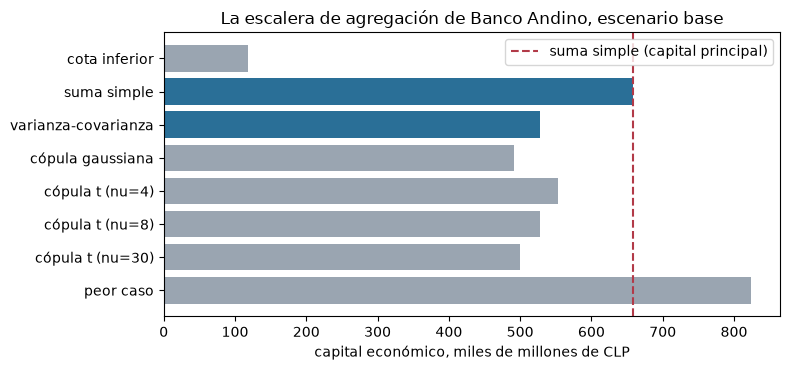

lower-bound          nu=None  capital    118,518  parte de la suma simple 0.1801  information-not-capital
simple-sum           nu=None  capital    658,046  parte de la suma simple 1.0000  headline-capital
variance-covariance  nu=None  capital    528,106  parte de la suma simple 0.8025  information-not-capital
gaussian-copula      nu=None  capital    491,974  parte de la suma simple 0.7476  information-not-capital
t-copula             nu=4.0   capital    552,389  parte de la suma simple 0.8394  information-not-capital
t-copula             nu=8.0   capital    528,321  parte de la suma simple 0.8029  information-not-capital
t-copula             nu=30.0  capital    499,128  parte de la suma simple 0.7585  information-not-capital
worst-case           nu=None  capital    823,332  parte de la suma simple 1.2512  information-not-capital


In [11]:
# Dibujar la banda versionada como barras con la suma simple como línea vertical, y marcar las filas recalculadas aquí
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple", "variance-covariance": "varianza-covarianza",
         "gaussian-copula": "cópula gaussiana", "t-copula": "cópula t", "worst-case": "peor caso"}
labels = [NAMES[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in agg["band"]]
values = [r["capital_clp_m"] / 1e3 for r in agg["band"]]
recomputed = {"suma simple", "varianza-covarianza"}
colours = ["#2a6f97" if label in recomputed else "#9aa5b1" for label in labels]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(labels[::-1], values[::-1], color=colours[::-1])
ax.axvline(total_simple / 1e3, color="#b23a48", linestyle="--", label="suma simple (capital principal)")
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_title("La escalera de agregación de Banco Andino, escenario base")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
for r in agg["band"]:
    print(f'{r["method"]:20s} nu={str(r["nu"]):5s} capital {r["capital_clp_m"]:10,.0f}  parte de la suma simple {r["diversification_factor"]:.4f}  {r["status"]}')

- **Los cuatro capitales suman CLP 658.046 millones**, el capital principal del caso, y la suma del motor es igual a la versionada.
- **La matriz de correlación versionada es válida** (menor valor propio 0,5), y el motor rechaza las tres inválidas con un motivo cada una.
- **La regla de la raíz cuadrada da CLP 528.106 millones**, 80,25 por ciento de la suma simple, un beneficio de 19,75 por ciento, e iguala la fila versionada. Los dos límites se comportan como se dijo: la independencia da 394.019 y la dependencia perfecta devuelve la suma simple.
- **El beneficio es función de la correlación.** Con una correlación común es 40,1 por ciento en 0, 17,6 por ciento en 0,5 y nada en 1: un beneficio de diversificación es tan creíble como la matriz que lo respalda, y aquí esa matriz es una convención.
- **El riesgo operacional recibe el mayor beneficio de Euler, 41,6 por ciento, y el de mercado el menor, 22,4 por ciento.** Esos beneficios son sobre la pérdida esperada en la cola del agregado con cópula gaussiana, así que no son comparables con el 19,75 por ciento del total de varianza-covarianza.
- **El peor caso, CLP 823.332 millones, es 1,2512 veces la suma simple.** La prueba de signo es verde en las filas diversificadas (mayor factor 0,8394) y roja al incluir el peor caso: la suma simple no es una cota superior para un VaR.
- **El exceso aditivo de este caso, 33,76 por ciento, cae dentro del 30 a 40 por ciento publicado.** El banco de referencia del artículo tiene otros pesos, así que es una consistencia que anotar y no una validación de Banco Andino.

Lo que este cuaderno no muestra: las filas con cópula de la banda se leyeron, no se recalcularon, porque el documento tiene números resumen y no las pérdidas simuladas (el cuaderno 02 construye una simulación); y Banco Andino es sintético, así que ninguna de estas cifras es una afirmación sobre un banco real.

## Resumen

- El capital económico es el VaR menos la pérdida esperada, por riesgo, a un año y al 99,9 por ciento; el documento tiene los cuatro números de cada uno de los cuatro riesgos.
- La suma simple es el capital principal; la regla de la raíz cuadrada necesita una matriz de correlación válida, que `check_correlation` hace cumplir.
- El factor de diversificación es el total sobre la suma de los capitales; su beneficio se agota cuando la correlación sube a 1.
- Las contribuciones de Euler suman el total y dan a cada riesgo su propio beneficio.
- Un VaR no es subaditivo: el peor caso versionado supera la suma simple, así que la suma no es una cota superior, y la prueba de signo se pone roja cuando se lo incluye.
- El rango de Rosenberg y Schuermann es una referencia para leer al lado del resultado, nunca un umbral.

**Qué probar a continuación.** Cambia una entrada fuera de la diagonal de la matriz del paso 3 y mira moverse el factor del paso 5. Luego sigue con el cuaderno 02, que reemplaza la regla de la raíz cuadrada por cópulas y muestra de dónde salen las filas gaussiana y t versionadas.

## Referencias

- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. y Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, en Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (las funciones de agregación del motor) y `docs/design/features/c18/requirements.md` (los requisitos del caso).